# Phase 2 — Models, experiments and results

This notebook walks through the Phase 2 modelling and evaluation work of **SmartCart**, the
offline grocery-basket assistant. It reads the result files that the committed scripts
produced and shows every comparison as a table or chart.

**Where the work itself lives.** Training and evaluation are scripts, so that every result
can be rebuilt with one command and checked with `--check`:

| Step | Script | Output read here |
| --- | --- | --- |
| Baseline intent model (TF-IDF + LinearSVC, grid search on validation) | `scripts/run_baseline.py` | `results/metrics/E0_intent_tuning.json` |
| DistilBERT intent and slot models, 3 seeds | `scripts/train_nlu.py` (about 75 min on a CPU) | `results/metrics/nlu_training_log.json` |
| Locked test evaluation of every model and pipeline | `scripts/evaluate_all.py` | `results/metrics/test_components.json`, `results/metrics/runs/`, `results/tables/` |

**Prices in the catalog are simulated (PKR).** The test sets were locked by hash before any
model saw them and evaluated once, with frozen configurations.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, Markdown, display

ROOT = Path.cwd()
while not (ROOT / "configs").is_dir() or not (ROOT / "results").is_dir():
    ROOT = ROOT.parent
M = ROOT / "results" / "metrics"
FIG = ROOT / "results" / "figures"

def load(path):
    return json.loads((ROOT / path).read_text(encoding="utf-8"))

def md_table(path):
    """Read the first Markdown table in a results/tables file into a DataFrame."""
    lines = [l for l in (ROOT / path).read_text(encoding="utf-8").splitlines() if l.startswith("|")]
    rows = [[c.strip() for c in l.strip("|").split("|")] for l in lines]
    return pd.DataFrame(rows[2:], columns=rows[0])

pd.set_option("display.max_colwidth", 60)

## 1. Problem and models compared

A shopper types a request (*"vegetarian pasta for four under 2,000 rupees, I already have
250 g of flour"*). SmartCart must turn it into a complete basket of whole product packs
within budget and diet, ask a question when the request is ambiguous, or prove that no
valid basket exists. Three components are learned or chosen, and for each one we compare
at least two alternatives:

| Component | Model A (baseline) | Model B |
| --- | --- | --- |
| Request parser (intent + slots) | TF-IDF + LinearSVC intent classifier, dictionary and rule slots | Fine-tuned DistilBERT (sequence classification for intent, token classification for 21 BIO slot tags), 3 seeds |
| Product retrieval | TF-IDF (word 1–2-grams) | MiniLM sentence embeddings + exact FAISS index |
| Basket selection | Cheapest product per line, then filter by diet and budget | OR-Tools CP-SAT with the hard rules applied before selection |
| Next-basket ranking (Track B) | Popularity; personal purchase frequency | Frequency + association rules (FP-Growth) |

**Data splits.** 900 annotated requests split 600 / 150 / 150 (train / validation / test)
by seed and by phrasing template, so validation and test use templates never seen in
training; 200 test and 50 development basket scenarios; 100 test and 50 development
retrieval queries; Instacart users split by order (last order = test).

## 2. Hyperparameter tuning — baseline intent classifier

The baseline's TF-IDF + LinearSVC classifier was tuned on the **validation** set over 15
configurations (analyzer, n-gram range, C). The highest validation macro-F1 was kept.

,analyzer,ngram_range,C,val_macro_f1,val_accuracy
0,char_wb,"(2, 4)",0.10,0.837479,0.833333
1,word+char,"((1, 2), (2, 4))",0.10,0.821876,0.806667
2,char_wb,"(2, 4)",0.30,0.819353,0.800000
3,char_wb,"(2, 4)",1.00,0.783421,0.753333
4,char_wb,"(2, 4)",0.03,0.781692,0.806667
5,word,"(1, 2)",0.10,0.780128,0.780000
6,word+char,"((1, 2), (2, 4))",0.03,0.777122,0.793333
7,word+char,"((1, 2), (2, 4))",0.30,0.772643,0.740000


selected: {'analyzer': 'char_wb', 'ngram_range': '(2, 4)', 'C': np.float64(0.1), 'val_macro_f1': np.float64(0.837479), 'val_accuracy': np.float64(0.833333)}


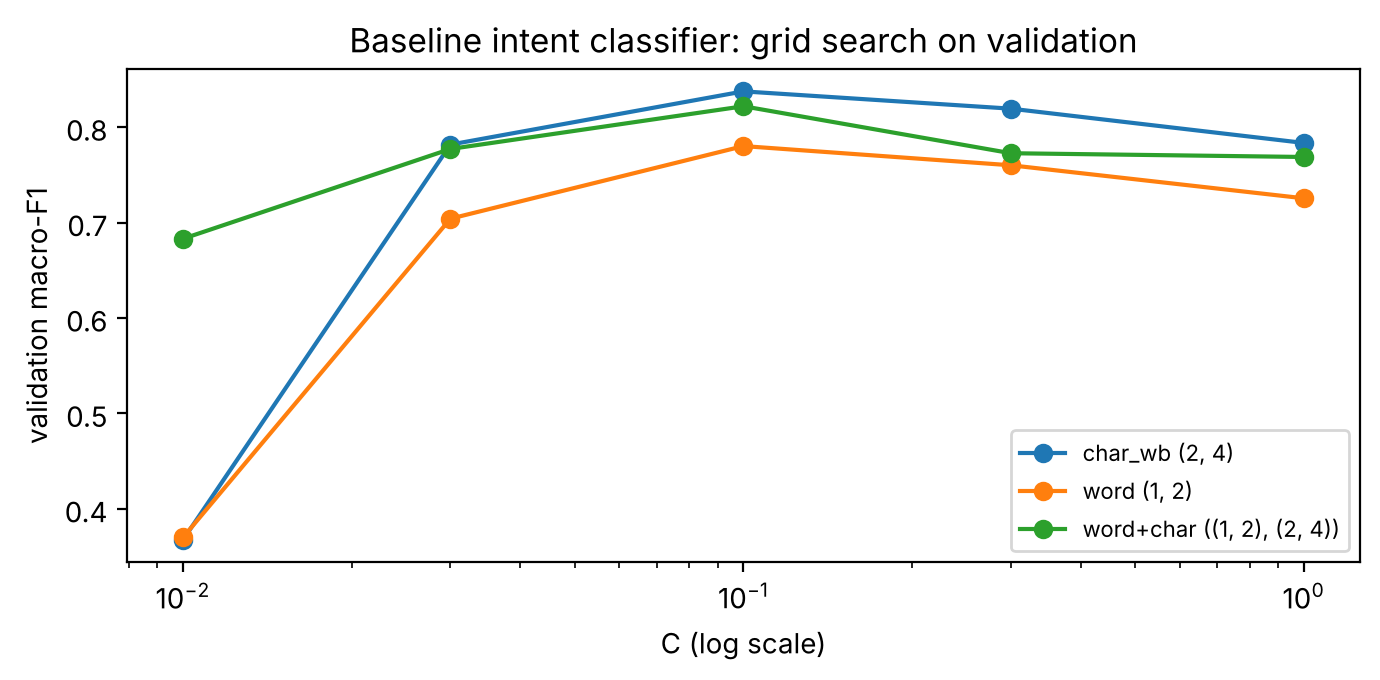

In [2]:
tuning = load("results/metrics/E0_intent_tuning.json")
rows = []
for g in tuning["grid"]:
    v, c = g["config"]["vectorizer"], g["config"]["classifier"]
    ngrams = tuple(v["ngram_range"]) if "ngram_range" in v else (tuple(v["word_ngram_range"]), tuple(v["char_ngram_range"]))
    rows.append({"analyzer": v["analyzer"], "ngram_range": str(ngrams), "C": c["C"],
                 "val_macro_f1": g["dev_macro_f1"], "val_accuracy": g["dev_accuracy"]})
grid = pd.DataFrame(rows)
best = grid.loc[grid.val_macro_f1.idxmax()]
display(grid.sort_values("val_macro_f1", ascending=False).head(8).reset_index(drop=True))
print("selected:", dict(best))

fig, ax = plt.subplots(figsize=(7, 3.5))
for (an, ng), g in grid.groupby(["analyzer", "ngram_range"]):
    ax.plot(g["C"], g["val_macro_f1"], marker="o", label=f"{an} {ng}")
ax.set_xscale("log"); ax.set_xlabel("C (log scale)"); ax.set_ylabel("validation macro-F1")
ax.set_title("Baseline intent classifier: grid search on validation"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 3. DistilBERT training (3 seeds)

Each seed trains two models on the 600 training examples (AdamW, learning rate 5e-5,
batch 16, warm-up 10%); the epoch with the best **validation** score is kept. Training
loss keeps falling while the validation score levels off within a few epochs.

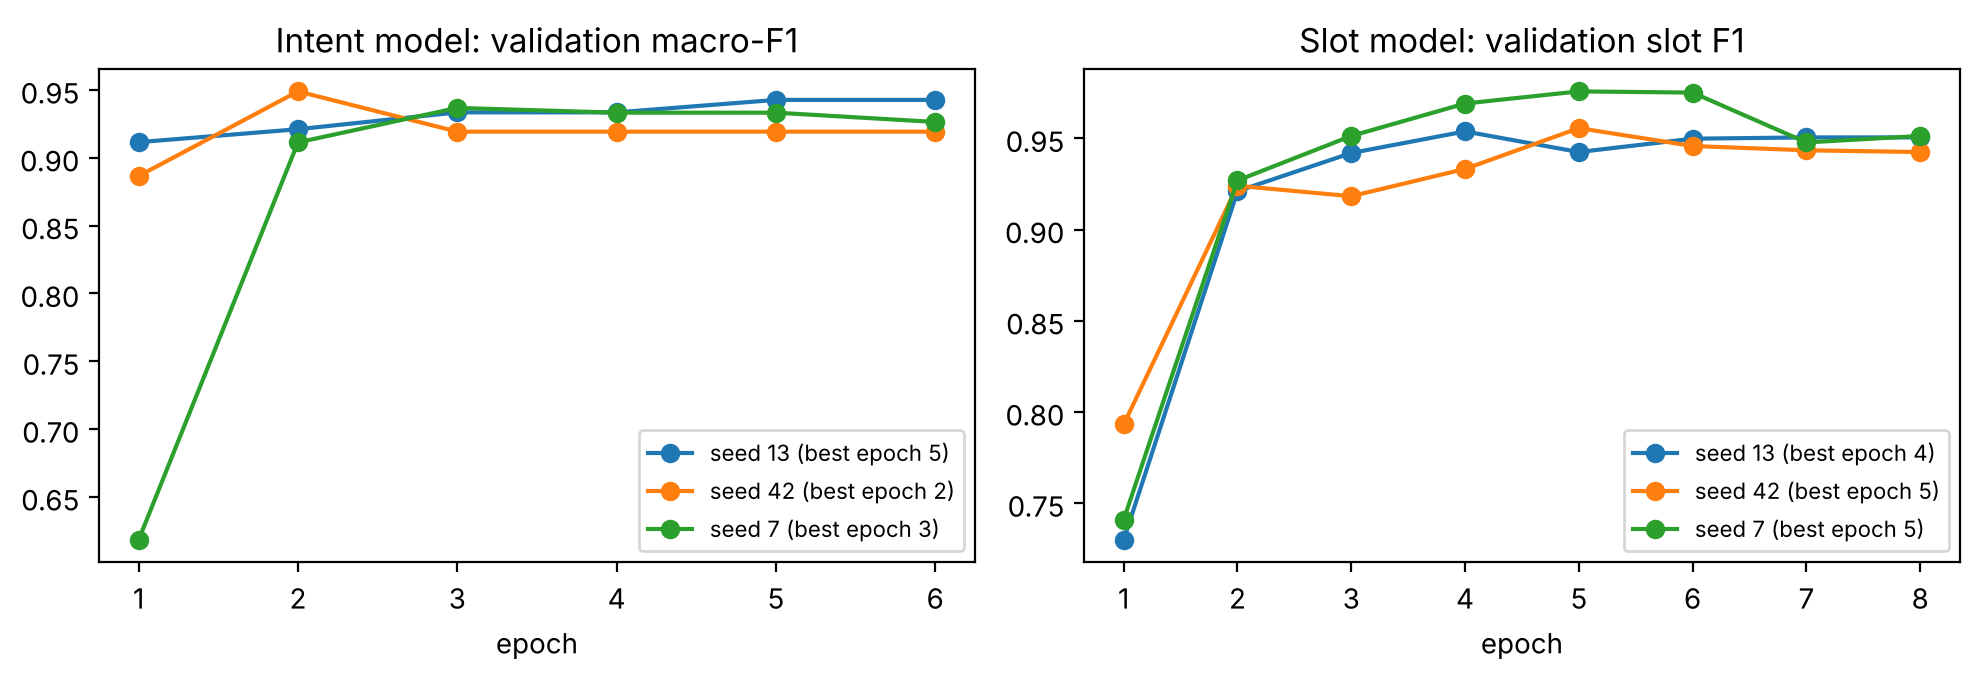

,run,best_epoch,best_val_score
0,seed13_intent,5,0.942647
1,seed13_slots,4,0.953800
2,seed42_intent,2,0.948932
3,seed42_slots,5,0.955606
4,seed7_intent,3,0.936751
5,seed7_slots,5,0.975758


In [3]:
log = load("results/metrics/nlu_training_log.json")["runs"]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for name, run in log.items():
    ax = axes[0] if run["task"] == "intent" else axes[1]
    ep = [e["epoch"] for e in run["epochs"]]
    ax.plot(ep, [e["dev_score"] for e in run["epochs"]], marker="o", label=f"seed {run['seed']} (best epoch {run['best_epoch']})")
axes[0].set_title("Intent model: validation macro-F1"); axes[1].set_title("Slot model: validation slot F1")
for ax in axes: ax.set_xlabel("epoch"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
pd.DataFrame([{"run": k, "best_epoch": v["best_epoch"], "best_val_score": v["best_dev_score"]} for k, v in log.items()])

## 4. Parser evaluation on the locked test set

Metrics: intent macro-F1 (the classes are imbalanced, so accuracy alone would hide the
small classes), entity-level slot micro-F1, and whole-request exact match.

,E0 baseline,DistilBERT (mean of 3 seeds)
intent macro-F1 (classifier only),0.788,0.936
intent macro-F1,0.842,0.947
slot micro-F1,0.947,0.972
request exact match,0.773,0.862


,E0 baseline,DistilBERT seed 13,DistilBERT seed 42,DistilBERT seed 7
build_grocery_list,0.861,1.000,1.000,1.000
plan_meal,0.840,0.992,0.930,0.952
revise_basket,0.983,0.983,0.983,0.983
unsupported,0.684,0.958,0.750,0.837


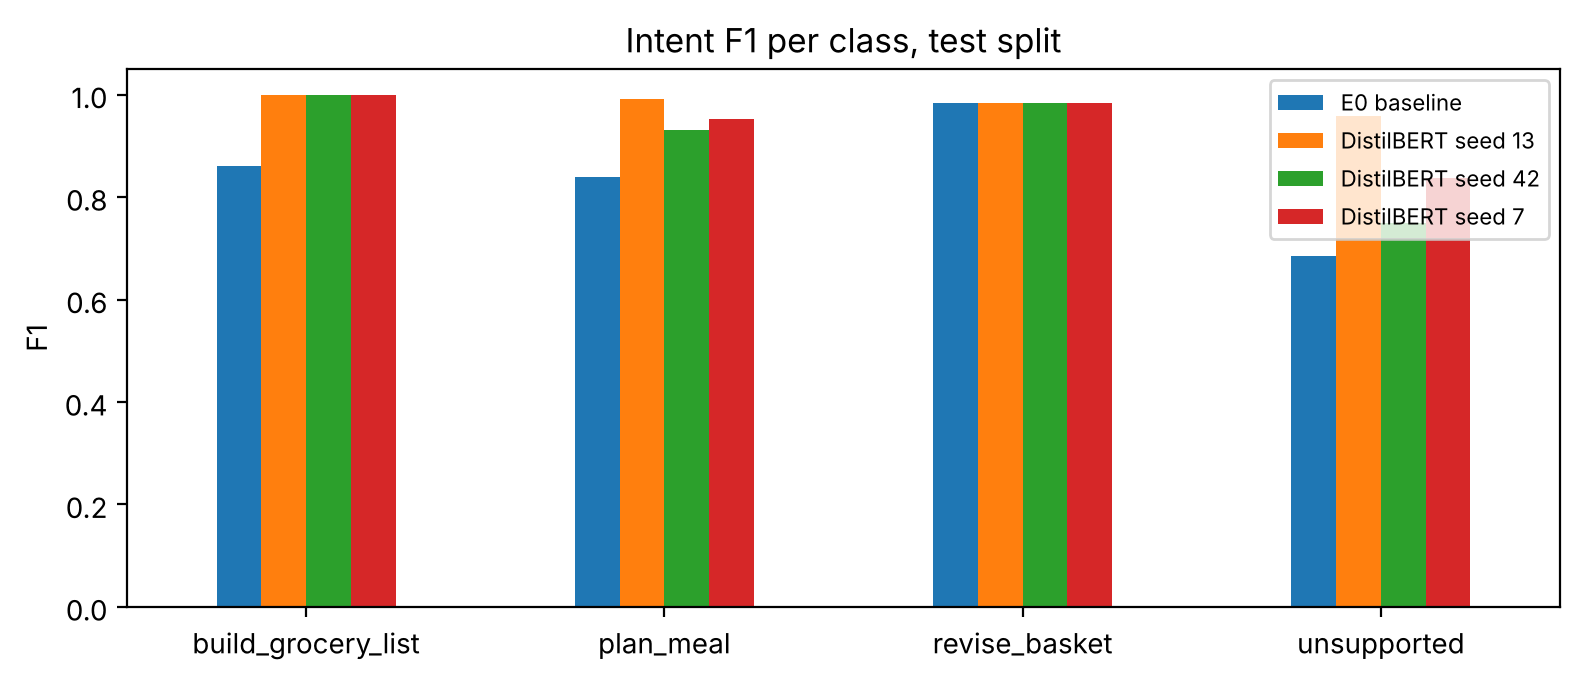

In [4]:
comp = load("results/metrics/test_components.json")["nlu"]
base, tr = comp["baseline"], comp["transformer"]
summary = pd.DataFrame({
    "E0 baseline": {"intent macro-F1 (classifier only)": base["intent_classifier_only"]["macro_f1"],
                    "intent macro-F1": base["intent"]["macro_f1"],
                    "slot micro-F1": base["slots"]["micro"]["f1"],
                    "request exact match": base["request_exact_match"]["accuracy"]},
    "DistilBERT (mean of 3 seeds)": {"intent macro-F1 (classifier only)": tr["summary"]["intent_macro_f1_classifier_only"]["mean"],
                    "intent macro-F1": tr["summary"]["intent_macro_f1"]["mean"],
                    "slot micro-F1": tr["summary"]["slot_micro_f1"]["mean"],
                    "request exact match": tr["summary"]["request_exact_match"]["mean"]},
}).round(3)
display(summary)

per_class = pd.DataFrame({"E0 baseline": {c: v["f1"] for c, v in base["intent"]["per_class"].items()}})
for seed, m in tr["per_seed"].items():
    per_class[f"DistilBERT seed {seed}"] = {c: v["f1"] for c, v in m["intent"]["per_class"].items()}
display(per_class.round(3))
per_class.plot.bar(figsize=(8, 3.5), rot=0, title="Intent F1 per class, test split")
plt.ylabel("F1"); plt.ylim(0, 1.05); plt.legend(fontsize=8); plt.tight_layout(); plt.show()

Confusion matrices on the test split (rows = true intent, columns = predicted), for the
baseline and DistilBERT seed 42, then the validation-versus-test comparison:

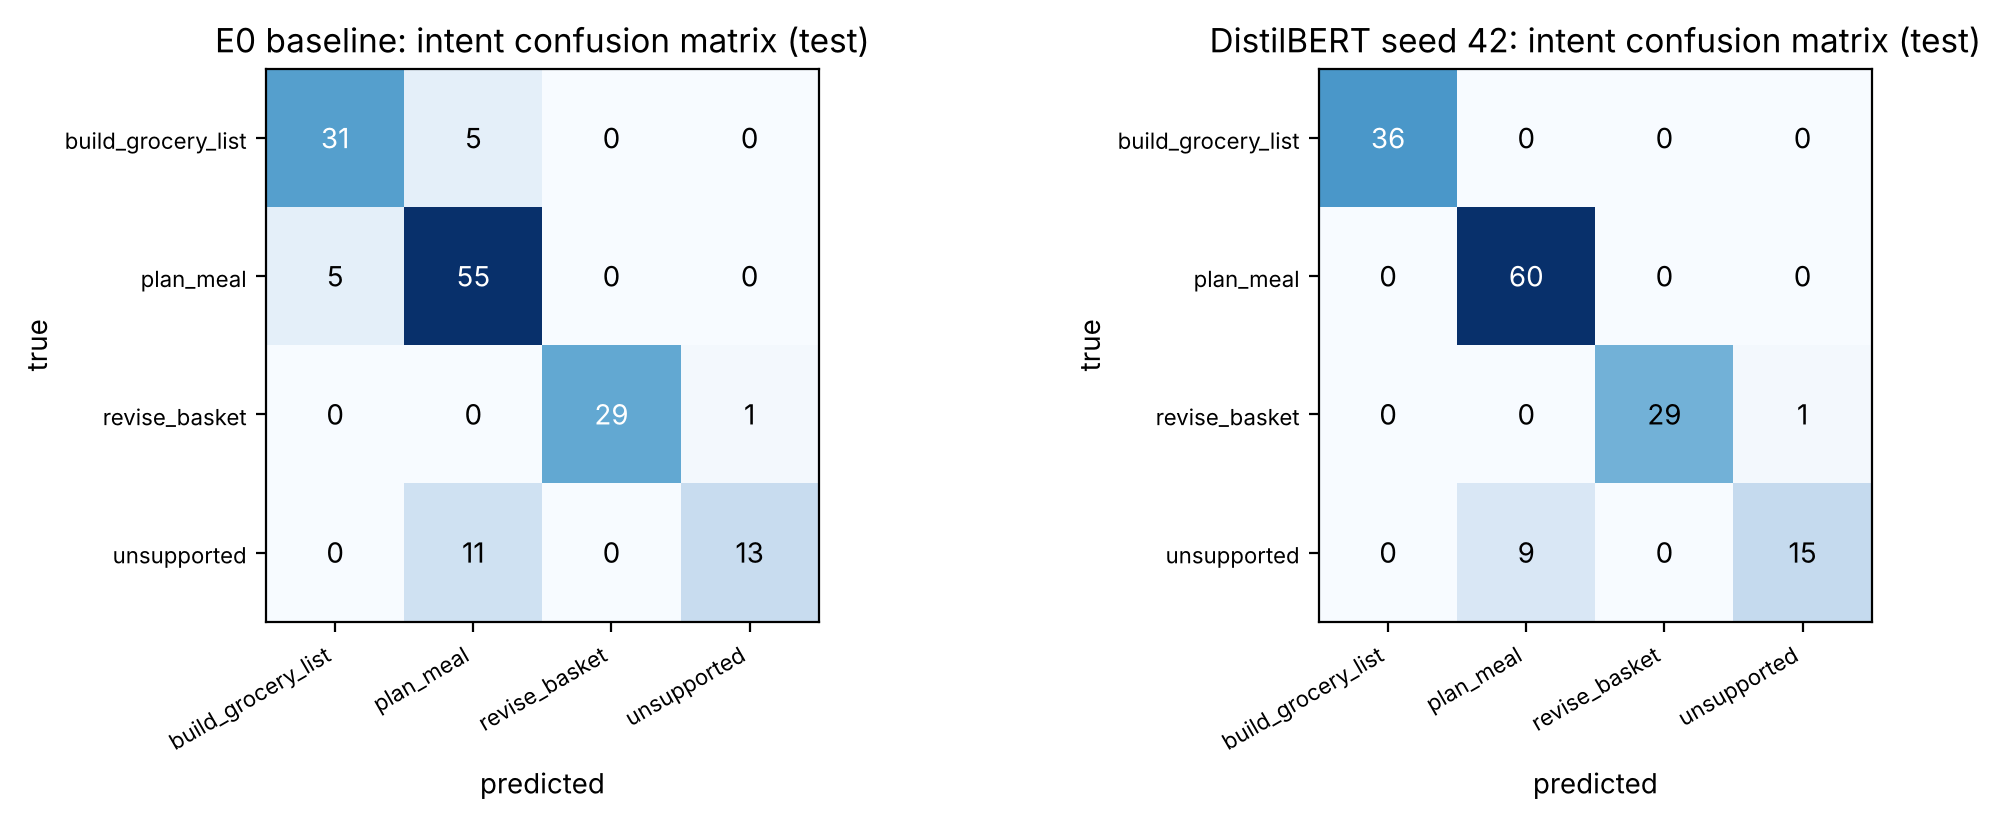

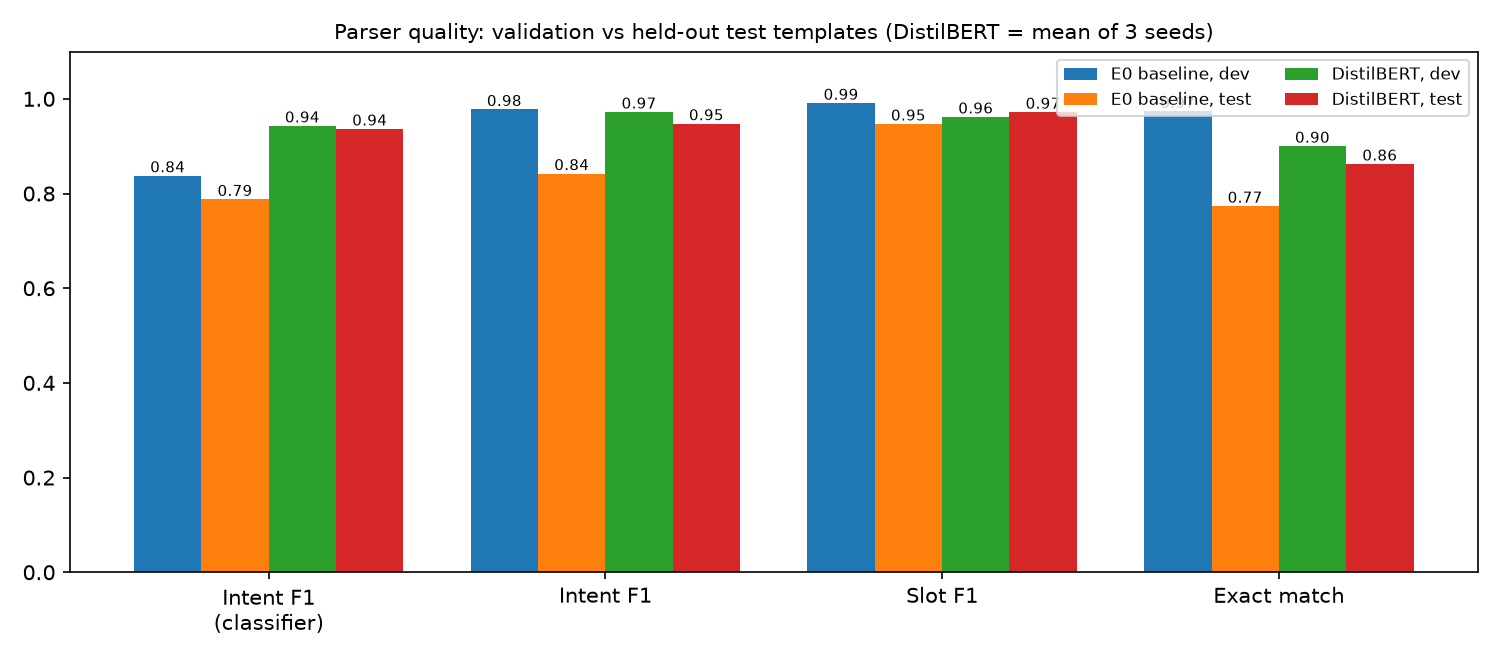

In [5]:
import numpy as np
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, (title, m) in zip(axes, [("E0 baseline", base["intent"]), ("DistilBERT seed 42", tr["per_seed"]["42"]["intent"])]):
    cm = np.array(m["confusion_matrix"]); labels = m["labels"]
    ax.imshow(cm, cmap="Blues")
    ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels, rotation=30, ha="right", fontsize=8)
    ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels, fontsize=8)
    for i in range(len(labels)):
        for j in range(len(labels)):
            ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set_title(f"{title}: intent confusion matrix (test)"); ax.set_xlabel("predicted"); ax.set_ylabel("true")
plt.tight_layout(); plt.show()
display(Image(filename=str(FIG / "14_parser_errors_test.png"), width=800))

## 5. Retrieval: TF-IDF vs MiniLM (100 test queries)

Metrics: Recall@5, Recall@10 and MRR over the whole 466-product catalog.

,Setting,Recall@5,Recall@10,MRR,R@10 brand,R@10 constrained,R@10 misspelling,R@10 near_match,R@10 synonym,R@10 transliteration
0,"tfidf_legacy_top10 (tfidf, legacy)",0.552,0.610,0.562,0.615,0.857,0.432,0.882,0.772,0.056
1,"tfidf (tfidf, display_name_ingredient)",0.549,0.610,0.555,0.615,0.857,0.432,0.882,0.772,0.056
2,"minilm (minilm, display_name_ingredient)",0.696,0.764,0.713,0.827,1.000,0.909,0.941,0.902,0.111


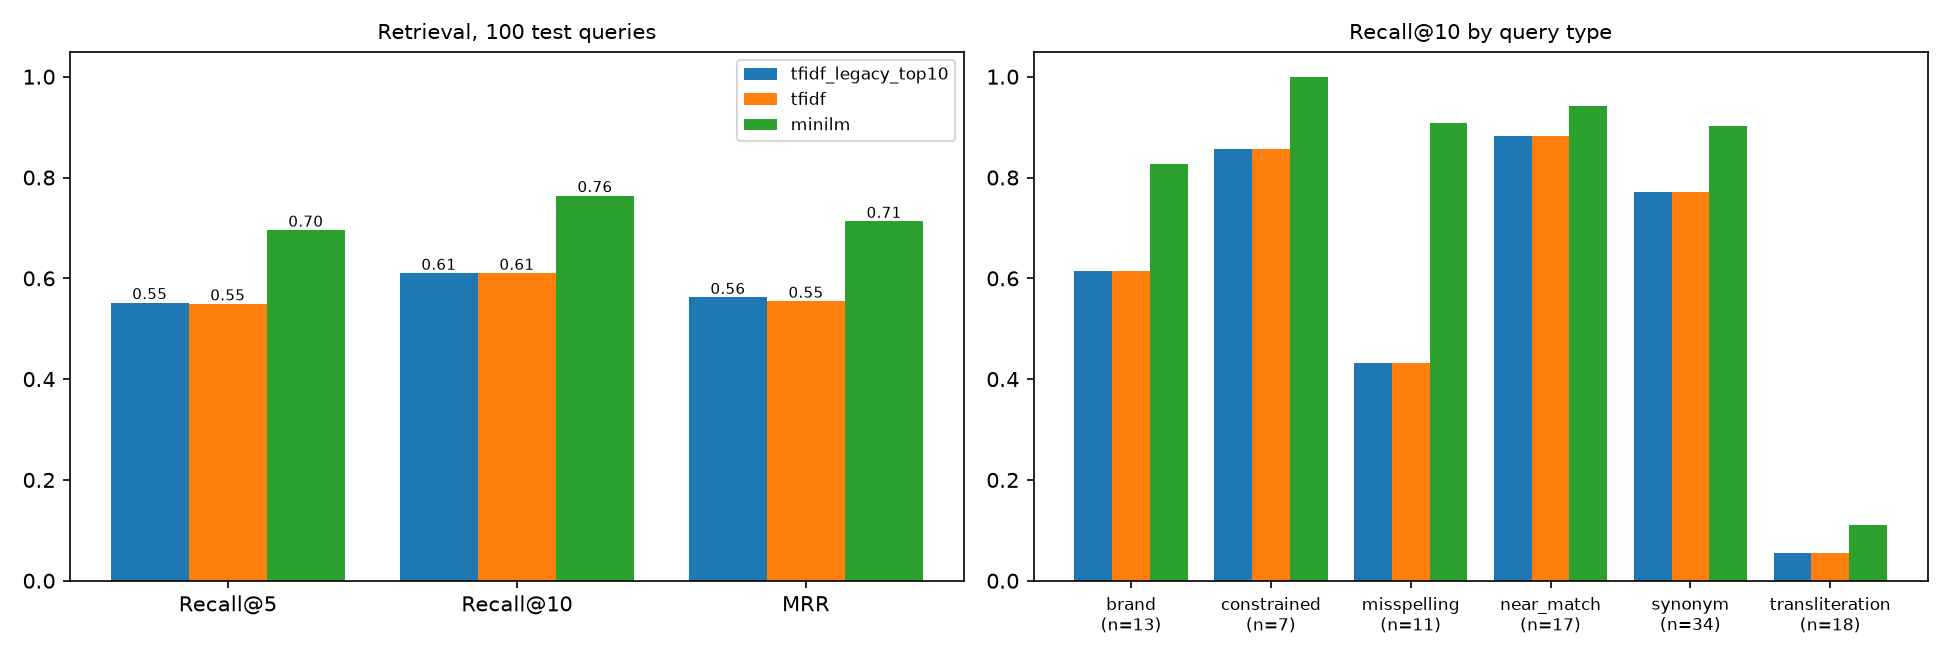

In [6]:
display(md_table("results/tables/retrieval.md"))
display(Image(filename=str(FIG / "15_retrieval_test.png"), width=900))

## 6. Full pipelines on 200 basket scenarios

Runs swap one component at a time: E0 (baseline everything) → E1 (+DistilBERT) → E2
(+MiniLM) → E3 (+CP-SAT) → E4 (+association terms); A1–A4 are ablations of E4. Each run is
scored with the **gold** request given to the selector (isolates selection) and **end to
end** from the raw text (DistilBERT runs: 3 seeds).

,Run,Mode,Feasible success,Coverage,Valid outputs / violations,Infeasible detected,False rejections,Clarification success,Unnecessary questions,Timeouts
0,E0,gold_input,112 / 120,0.976,140 / 0,40 / 40,18,30 / 40,0,0
1,E0,end_to_end,109 / 120,0.959,134 / 0,39 / 40,19,26 / 40,2,0
2,E1,gold_input,112 / 120,0.976,140 / 0,40 / 40,18,30 / 40,0,0
3,E1,end_to_end,92.0 (91–93) / 120.0,0.851,122.3 (121–124) / 3.0 (2–4),32.7 (32–34) / 40.0,19.0 (17–21),27.0 (25–29) / 40.0,23.0 (22–24),0
4,E2,gold_input,112 / 120,0.976,140 / 0,40 / 40,18,30 / 40,0,0
5,E2,end_to_end,92.0 (91–93) / 120.0,0.851,122.3 (121–124) / 3.0 (2–4),32.7 (32–34) / 40.0,19.0 (17–21),27.0 (25–29) / 40.0,23.0 (22–24),0
6,E3,gold_input,120 / 120,1.000,158 / 0,40 / 40,0,40 / 40,0,0
7,E3,end_to_end,97.0 (96–98) / 120.0,0.822,136.0 (135–137) / 3.0 (2–4),32.7 (32–34) / 40.0,5.3 (4–7),35.7 (33–38) / 40.0,23.0 (22–24),0
8,E4,gold_input,120 / 120,1.000,158 / 0,40 / 40,0,40 / 40,0,0
9,E4,end_to_end,97.0 (96–98) / 120.0,0.822,136.0 (135–137) / 3.0 (2–4),32.7 (32–34) / 40.0,5.3 (4–7),35.7 (33–38) / 40.0,23.0 (22–24),0


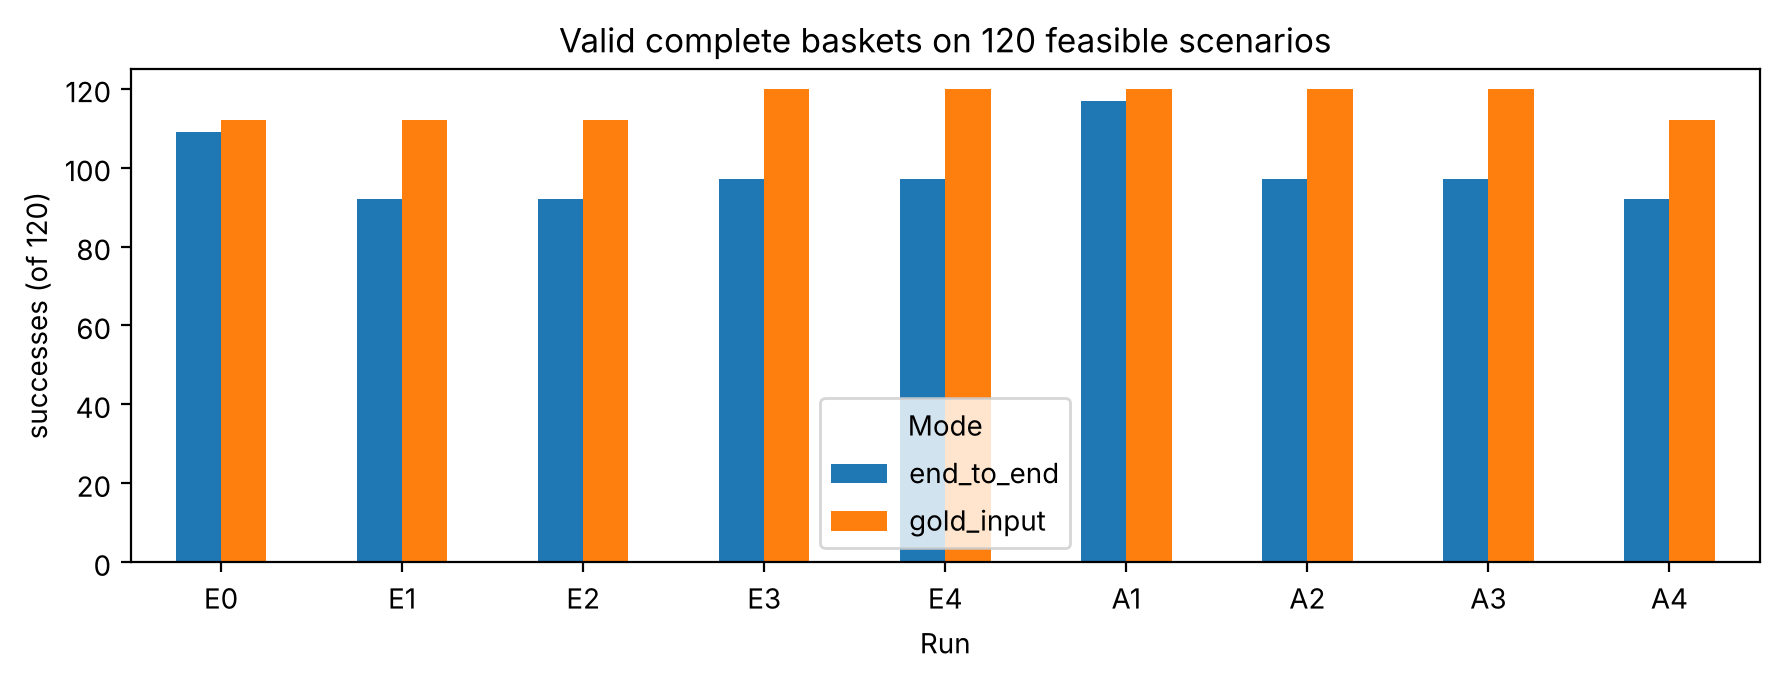

In [7]:
baskets = md_table("results/tables/baskets.md")
display(baskets)

def mean_of(cell):
    return float(cell.split(" ")[0].split("/")[0])

runs = {}
for r in ["E0", "E1", "E2", "E3", "E4", "A1", "A2", "A3", "A4"]:
    m = load(f"results/metrics/runs/{r}.json")
    runs[r] = m
rows = baskets.copy()
rows["success"] = rows["Feasible success"].map(mean_of)
pivot = rows.pivot(index="Run", columns="Mode", values="success").reindex(["E0","E1","E2","E3","E4","A1","A2","A3","A4"])
ax = pivot.plot.bar(figsize=(9, 3.5), rot=0, title="Valid complete baskets on 120 feasible scenarios")
ax.set_ylabel("successes (of 120)"); ax.set_ylim(0, 125); plt.tight_layout(); plt.show()

## 7. Which differences are real? Paired bootstrap over scenario families

Differences in scenario success with a 95% interval (2,000 resamples over the 24 test
families). An interval that excludes 0 is a reliable difference.

,Comparison,gold_input,end_to_end
0,E1 - E0,"+0.000 [+0.000, +0.000]","-0.112 [-0.191, -0.048]"
1,E2 - E1,"+0.000 [+0.000, +0.000]","+0.000 [+0.000, +0.000]"
2,E3 - E2,"+0.090 [+0.064, +0.117]","+0.068 [+0.041, +0.096]"
3,E4 - E3,"+0.000 [+0.000, +0.000]","+0.000 [+0.000, +0.000]"
4,E4 - E0,"+0.090 [+0.064, +0.117]","-0.043 [-0.131, +0.032]"
5,A1 - E4,"+0.000 [+0.000, +0.000]","+0.133 [+0.062, +0.218]"
6,A2 - E4,"+0.000 [+0.000, +0.000]","+0.000 [+0.000, +0.000]"
7,A3 - E4,"+0.000 [+0.000, +0.000]","+0.000 [+0.000, +0.000]"
8,A4 - E4,"-0.090 [-0.117, -0.064]","-0.068 [-0.096, -0.041]"


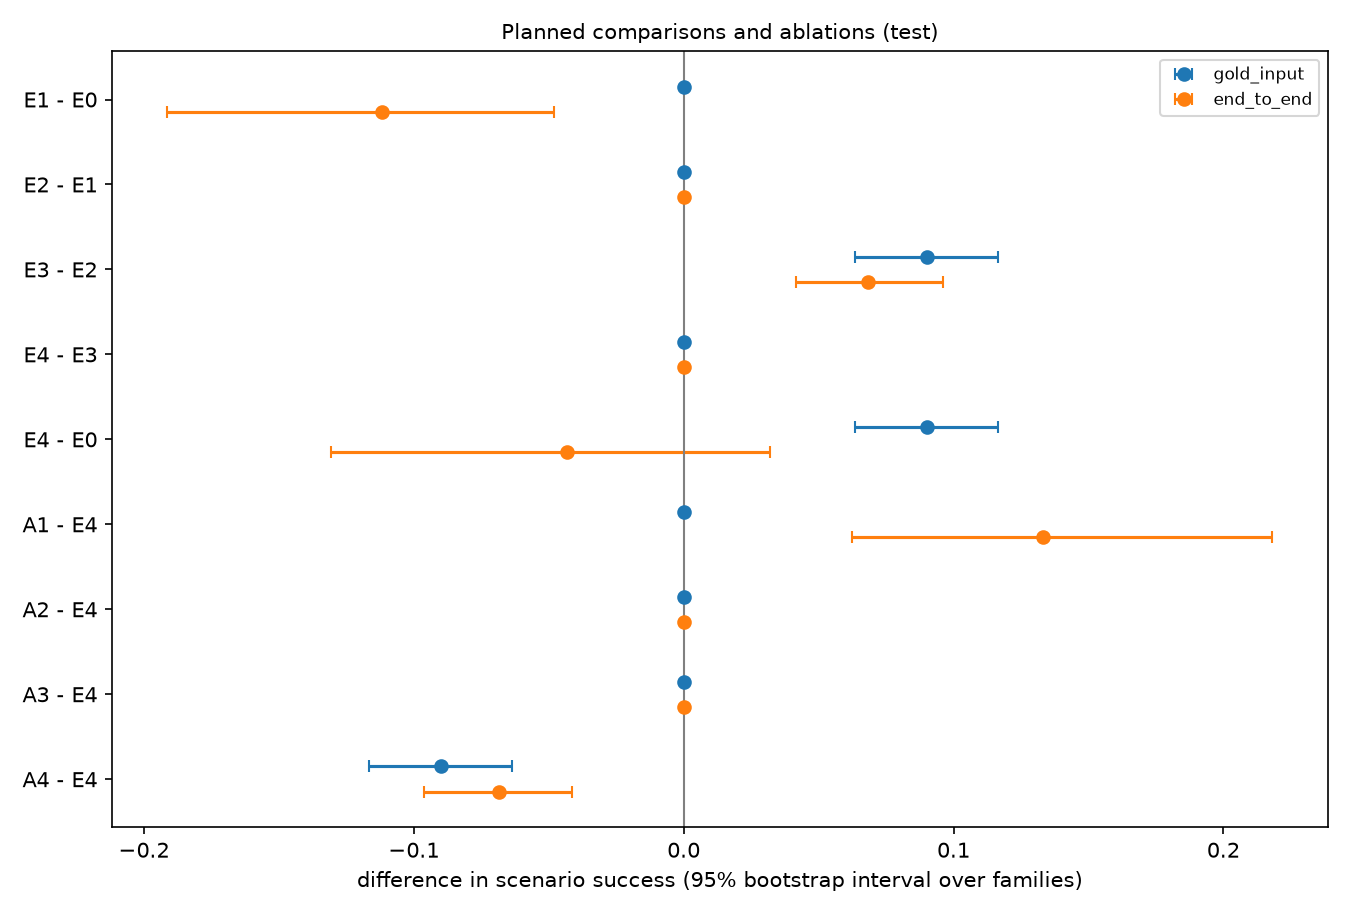

In [8]:
display(md_table("results/tables/comparisons.md"))
display(Image(filename=str(FIG / "17_ablations_test.png"), width=800))

## 8. Track B — next-basket ranking (7,413 Instacart users)

In [9]:
display(md_table("results/tables/track_b.md"))

,Ranker,Recall@10,NDCG@10,Repeat R@10,Repeat NDCG@10,New R@10,New NDCG@10
0,popularity,0.502,0.361,0.573,0.402,0.261,0.135
1,frequency,0.703,0.582,0.903,0.724,0.104,0.042
2,association,0.686,0.572,0.895,0.716,0.073,0.030
3,Paired bootstrap (users),Mean difference,95% interval,NaN,NaN,NaN,NaN
4,---,---,---,NaN,NaN,NaN,NaN
5,association_minus_frequency_ndcg_at_10,-0.0105,"[-0.0122, -0.0089]",NaN,NaN,NaN,NaN
6,association_minus_frequency_recall_at_10,-0.0170,"[-0.0204, -0.0135]",NaN,NaN,NaN,NaN
7,frequency_minus_popularity_ndcg_at_10,+0.2213,"[+0.2146, +0.2285]",NaN,NaN,NaN,NaN
8,frequency_minus_popularity_recall_at_10,+0.2015,"[+0.1928, +0.2102]",NaN,NaN,NaN,NaN


## 9. Response time

,Run,Cold load (s),gold_input p50 / p95 (s),end_to_end p50 / p95 (s)
0,E0,8.042,0.0477 / 0.091,0.0518 / 0.1047
1,E1,31.866,0.044 / 0.0874,0.2183 / 0.3705
2,E2,24.525,0.1092 / 0.228,0.2432 / 0.4238
3,E3,28.069,0.0138 / 0.0581,0.1635 / 0.2733
4,E4,26.062,0.0128 / 0.051,0.1688 / 0.2947
5,A1,19.115,0.0122 / 0.0655,0.0164 / 0.0346
6,A2,16.908,0.0128 / 0.0399,0.1694 / 0.322
7,A3,20.92,0.0138 / 0.0589,0.1182 / 0.1841
8,A4,13.72,0.0802 / 0.1314,0.1814 / 0.2584


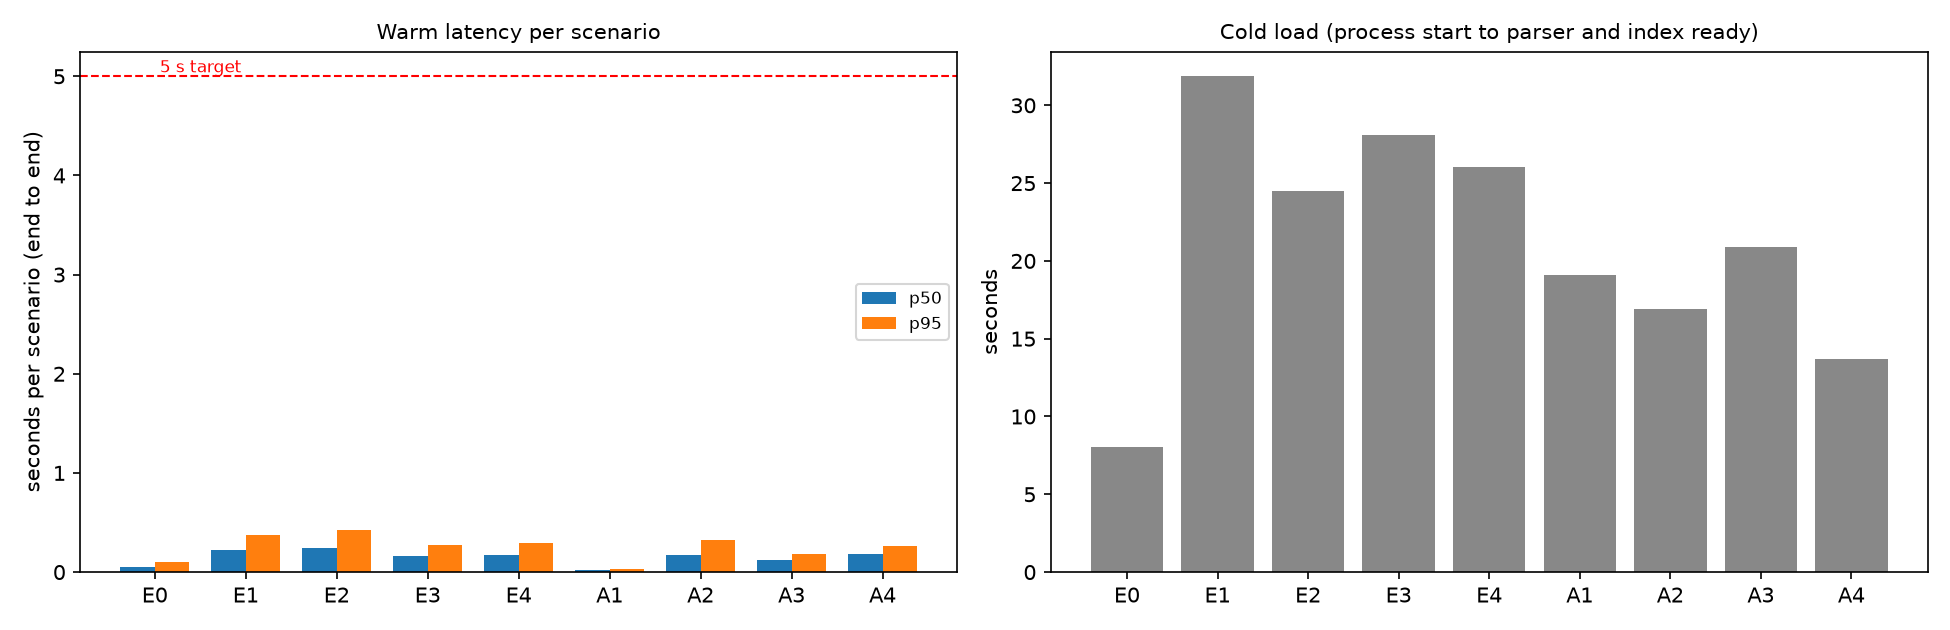

In [10]:
display(md_table("results/tables/latency.md"))
display(Image(filename=str(FIG / "18_latency_test.png"), width=900))

## 10. Analysis and conclusion

**Which model performed best, and why.**

- *Parser:* DistilBERT is the better NLU model on the test set (intent macro-F1 0.947 vs
  0.842, exact match 0.862 vs 0.773), mainly on revisions, unsupported requests and
  grocery lists. But inside the full pipeline the **rule-based baseline parser wins end to
  end** (A1 192/200 vs E4 164–168/200, +0.133 [+0.062, +0.218]). The basket test is
  mostly meal requests with phrasings never seen in training ("We're having…", "for a
  family of 4, 743 is my limit"), which DistilBERT misreads and the baseline's
  dictionaries handle. Caveat: the baseline's cue words were written alongside the
  benchmark generator, which may favour it.
- *Retrieval:* MiniLM beats TF-IDF (Recall@10 0.764 vs 0.610), especially on misspellings,
  brands and synonyms, but does not change any basket, because the pipeline searches with
  canonical ingredient names.
- *Selection:* CP-SAT gives the correct outcome on **all 200** scenarios when the request is
  understood (vs 182 for the cheapest-then-filter baseline, +0.090 [+0.064, +0.117]): it
  applies the diet before choosing, and it proves infeasibility with the budget that would
  work.
- *Associations:* no effect on baskets; slightly lower next-basket ranking than personal
  frequency.

**Where it fails.** Every end-to-end failure starts in the parser: a missed dish name, a
number attached to the wrong slot, an exclusion read as a pantry item, or a missed diet
(which can produce a basket that looks valid but breaks the user's real constraint).
Details: `docs/failure_analysis.md`.

**What could be improved.** Train the parser on more varied phrasings; confirm the
extracted constraints with the user before buying; handle transliterated ingredient names
(*kali mirch*, *makhan*) in retrieval; evaluate on requests written by real users; use a
catalog whose products differ within an ingredient.

**In practice.** When the request is understood, the system always returns a correct
basket or a correct "impossible, here is the budget that would work" — the remaining
risk is understanding the request, so the interface shows "What I understood" for the
user to check.